### Load and Review Final Test Evaluation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

# Locate processed data directory
project_root = Path.cwd()
processed_dir = project_root.parent / "data" / "processed"

# Locate model evaluation directory
evaluation_dir = project_root.parent / "models" / "evaluation"

# Load final test evaluation
evaluation_files = list(
    evaluation_dir.rglob("final_test_evaluation.csv")
)

if not evaluation_files:
    raise FileNotFoundError(
        "Final test evaluation file not found."
    )

final_evaluation = pd.read_csv(evaluation_files[0])

print("Final evaluation loaded successfully.")

display(final_evaluation)

Final evaluation loaded successfully.


,Unnamed: 0,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Average_Precision
0,Random Forest,0.940327,0.068827,0.643432,0.124352,0.954675,0.072159


### Load and Review the Final Confusion Matrix

In [2]:
confusion_matrix_path = list(
    evaluation_dir.rglob("final_confusion_matrix.csv")
)

if not confusion_matrix_path:
    raise FileNotFoundError(
        "Final confusion matrix file not found."
    )

final_confusion = pd.read_csv(confusion_matrix_path[0])

print("Final confusion matrix loaded successfully.")

display(final_confusion)

Final confusion matrix loaded successfully.


,Unnamed: 0,Predicted_Non_Adopter,Predicted_Adopter
0,Actual_Non_Adopter,53022,3247
1,Actual_Adopter,133,240


### Calculate Business-Level Model Metrics

In [3]:
tn = 53022
fp = 3247
fn = 133
tp = 240

total_users = tn + fp + fn + tp

business_metrics = pd.DataFrame({
    "Metric": [
        "Total Cohort Records",
        "Actual Adopters",
        "Predicted Adopters",
        "Correctly Identified Adopters",
        "Missed Adopters",
        "False Discovery Rate",
        "Adopter Identification Rate"
    ],
    "Value": [
        total_users,
        tp + fn,
        tp + fp,
        tp,
        fn,
        fp / (tp + fp),
        tp / (tp + fn)
    ]
})

business_metrics["Value"] = business_metrics["Value"].round(4)

display(business_metrics)

,Metric,Value
0,Total Cohort Records,56642.0000
1,Actual Adopters,373.0000
2,Predicted Adopters,3487.0000
3,Correctly Identified Adopters,240.0000
4,Missed Adopters,133.0000
5,False Discovery Rate,0.9312
6,Adopter Identification Rate,0.6434


### Analyze Feature Importance

In [6]:
# Locate the feature importance comparison file
interpretation_dir = project_root.parent / "models" / "interpretation"

importance_files = list(
    interpretation_dir.rglob(
        "random_forest_importance_comparison.csv"
    )
)

if not importance_files:
    raise FileNotFoundError(
        "Feature importance comparison file not found."
    )

# Load feature importance data
importance_comparison = pd.read_csv(importance_files[0])

print("Feature importance comparison loaded successfully.")

# Display the top 15 features by permutation importance
top_features = importance_comparison.sort_values(
    by="Importance_Mean",
    ascending=False
).head(15)

display(
    top_features[
        [
            "Feature",
            "Importance",
            "Importance_Mean",
            "Importance_Std",
            "Impurity_Rank",
            "Permutation_Rank"
        ]
    ]
)

Feature importance comparison loaded successfully.


,Feature,Importance,Importance_Mean,Importance_Std,Impurity_Rank,Permutation_Rank
0,signup_tenure_days,0.294306,0.035317,0.002760,1,1
1,has_adopted_analytics_dashboard,0.010406,0.003745,0.001882,18,2
2,organization_tenure_days,0.180498,0.003355,0.001603,2,3
3,has_adopted_webhooks,0.009305,0.002754,0.001372,23,4
4,subscription_tenure_days,0.100127,0.002602,0.001969,3,5
5,has_adopted_api_documentation,0.005682,0.002482,0.001493,32,6
6,has_adopted_api_authentication,0.009380,0.002356,0.001344,21,7
7,organization_company_size,0.007612,0.001863,0.000979,27,8
8,api_success_rate,0.015976,0.001233,0.000581,11,9
9,api_requests_products,0.004527,0.001076,0.000491,33,10


#### Inspect Feature Importance Column Names

In [5]:
print("Available columns:")
print(importance_comparison.columns.tolist())

print("\nFirst 5 rows:")
display(importance_comparison.head())

Available columns:
['Feature', 'Importance', 'Importance_Mean', 'Importance_Std', 'Impurity_Rank', 'Permutation_Rank']

First 5 rows:


,Feature,Importance,Importance_Mean,Importance_Std,Impurity_Rank,Permutation_Rank
0,signup_tenure_days,0.294306,0.035317,0.002760,1,1
1,has_adopted_analytics_dashboard,0.010406,0.003745,0.001882,18,2
2,organization_tenure_days,0.180498,0.003355,0.001603,2,3
3,has_adopted_webhooks,0.009305,0.002754,0.001372,23,4
4,subscription_tenure_days,0.100127,0.002602,0.001969,3,5


#### Display the Top 15 Important Features

In [7]:
top_features = importance_comparison.sort_values(
    "Importance_Mean",
    ascending=False
).head(15)

display(
    top_features[
        [
            "Feature",
            "Importance",
            "Importance_Mean",
            "Importance_Std",
            "Impurity_Rank",
            "Permutation_Rank"
        ]
    ]
)

,Feature,Importance,Importance_Mean,Importance_Std,Impurity_Rank,Permutation_Rank
0,signup_tenure_days,0.294306,0.035317,0.002760,1,1
1,has_adopted_analytics_dashboard,0.010406,0.003745,0.001882,18,2
2,organization_tenure_days,0.180498,0.003355,0.001603,2,3
3,has_adopted_webhooks,0.009305,0.002754,0.001372,23,4
4,subscription_tenure_days,0.100127,0.002602,0.001969,3,5
5,has_adopted_api_documentation,0.005682,0.002482,0.001493,32,6
6,has_adopted_api_authentication,0.009380,0.002356,0.001344,21,7
7,organization_company_size,0.007612,0.001863,0.000979,27,8
8,api_success_rate,0.015976,0.001233,0.000581,11,9
9,api_requests_products,0.004527,0.001076,0.000491,33,10


### Visualize the Top 15 Features

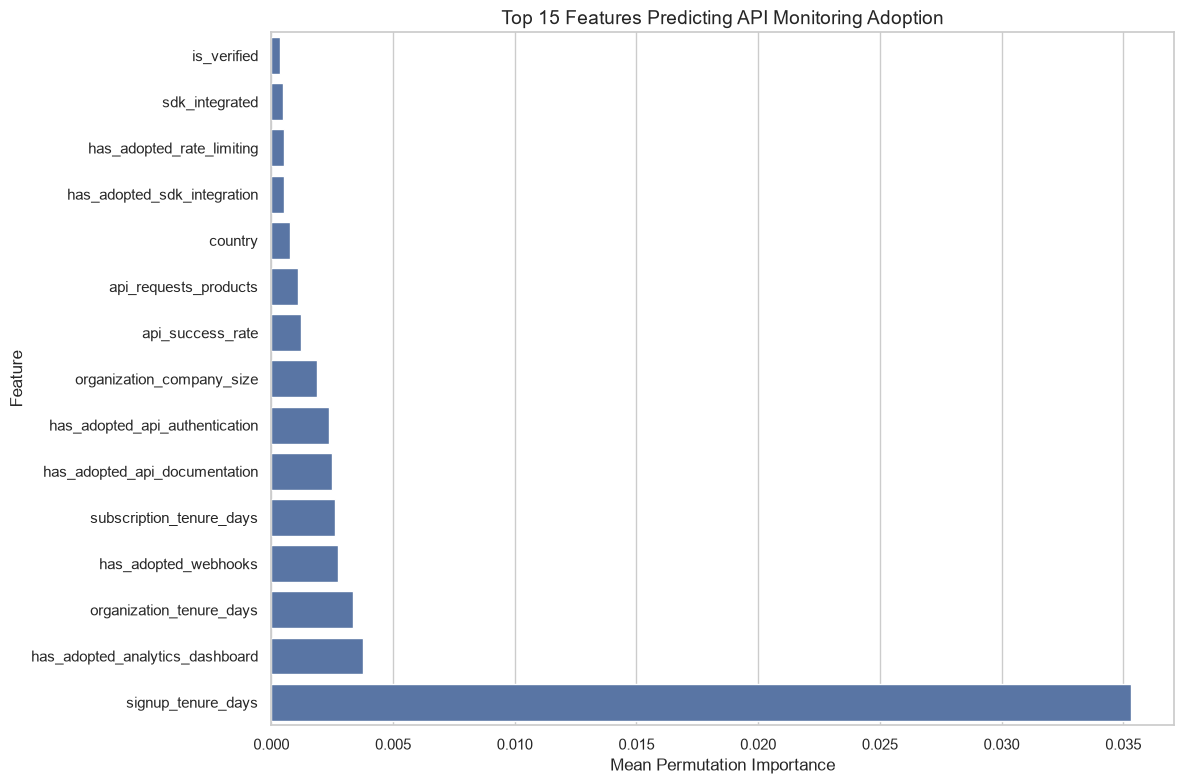

In [8]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_features.sort_values(
        "Importance_Mean",
        ascending=True
    ),
    x="Importance_Mean",
    y="Feature"
)

plt.title(
    "Top 15 Features Predicting API Monitoring Adoption",
    fontsize=14
)

plt.xlabel("Mean Permutation Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    "../visualizations/top_15_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Identify Key Business Problems

In [9]:
business_problems = pd.DataFrame({
    "Business_Area": [
        "User Activation",
        "Feature Discovery",
        "Product Engagement",
        "Subscription Lifecycle",
        "API Experience"
    ],
    "Observed_Finding": [
        "Signup tenure is the strongest adoption predictor.",
        "Previous analytics dashboard adoption is informative.",
        "Previous webhook, documentation, and authentication adoption are useful predictors.",
        "Organization and subscription tenure contribute to predictions.",
        "API success rate and product endpoint activity provide additional signals."
    ],
    "Potential_Business_Problem": [
        "New users may need more guidance to reach meaningful product value.",
        "Users may not discover or understand related product features.",
        "Users may need guidance to explore additional API capabilities.",
        "Users at different lifecycle stages may require different engagement strategies.",
        "API usage experience may influence users' readiness to explore more features."
    ],
    "Business_Opportunity": [
        "Improve onboarding and early activation.",
        "Promote relevant features through contextual education.",
        "Create targeted feature education campaigns.",
        "Design lifecycle-based engagement programs.",
        "Improve API documentation and developer support."
    ]
})

display(business_problems)

,Business_Area,Observed_Finding,Potential_Business_Problem,Business_Opportunity
0,User Activation,Signup tenure is the strongest adoption predic...,New users may need more guidance to reach mean...,Improve onboarding and early activation.
1,Feature Discovery,Previous analytics dashboard adoption is infor...,Users may not discover or understand related p...,Promote relevant features through contextual e...
2,Product Engagement,"Previous webhook, documentation, and authentic...",Users may need guidance to explore additional ...,Create targeted feature education campaigns.
3,Subscription Lifecycle,Organization and subscription tenure contribut...,Users at different lifecycle stages may requir...,Design lifecycle-based engagement programs.
4,API Experience,API success rate and product endpoint activity...,API usage experience may influence users' read...,Improve API documentation and developer support.


### Develop Product Recommendations

In [10]:
product_recommendations = pd.DataFrame({
    "Priority": [
        "High",
        "High",
        "High",
        "Medium",
        "Medium"
    ],
    "Business_Area": [
        "User Activation",
        "Feature Discovery",
        "Product Engagement",
        "Subscription Lifecycle",
        "API Experience"
    ],
    "Product_Recommendation": [
        "Create guided onboarding journeys for new users.",
        "Recommend API Monitoring to users who have adopted the analytics dashboard.",
        "Provide contextual feature education for webhooks, API documentation, and authentication.",
        "Develop lifecycle-based engagement campaigns for users at different tenure stages.",
        "Improve API documentation and provide developer support based on API usage patterns."
    ],
    "Success_Metric": [
        "New user activation rate",
        "API Monitoring adoption rate",
        "Feature discovery and adoption rate",
        "Feature adoption rate by lifecycle stage",
        "API success rate"
    ]
})

display(product_recommendations)

,Priority,Business_Area,Product_Recommendation,Success_Metric
0,High,User Activation,Create guided onboarding journeys for new users.,New user activation rate
1,High,Feature Discovery,Recommend API Monitoring to users who have ado...,API Monitoring adoption rate
2,High,Product Engagement,Provide contextual feature education for webho...,Feature discovery and adoption rate
3,Medium,Subscription Lifecycle,Develop lifecycle-based engagement campaigns f...,Feature adoption rate by lifecycle stage
4,Medium,API Experience,Improve API documentation and provide develope...,API success rate


### Document Model Limitation

In [11]:
model_limitations = pd.DataFrame({
    "Limitation": [
        "Synthetic Dataset",
        "Class Imbalance",
        "Low Precision",
        "Temporal Distribution Shift",
        "Repeated Users Across Cohorts",
        "Predictive Importance Is Not Causation",
        "Prediction Threshold",
        "Feature Interpretation"
    ],
    "Description": [
        "The project uses synthetic data and does not represent verified real-world customer behavior.",
        "Only 0.66% of the final test cohort records are positive examples.",
        "Only 6.88% of users predicted as adopters actually adopted the feature.",
        "The positive adoption rate differs between training and test periods.",
        "Some users appear in both training and test periods across different cohort dates.",
        "Feature importance identifies predictive relationships, not causal effects.",
        "The 0.55 threshold was selected using validation data based on F1-score.",
        "Some features may represent correlated or overlapping user behaviors."
    ],
    "Potential_Impact": [
        "Real-world performance may differ from the reported evaluation.",
        "Accuracy alone can be misleading.",
        "Product teams may need to review many false-positive predictions.",
        "Model performance may change as product usage patterns evolve.",
        "Results do not establish generalization to entirely unseen users.",
        "Product recommendations require further validation.",
        "Different business costs may justify a different threshold.",
        "Individual feature contributions should be interpreted carefully."
    ]
})

display(model_limitations)

,Limitation,Description,Potential_Impact
0,Synthetic Dataset,The project uses synthetic data and does not r...,Real-world performance may differ from the rep...
1,Class Imbalance,Only 0.66% of the final test cohort records ar...,Accuracy alone can be misleading.
2,Low Precision,Only 6.88% of users predicted as adopters actu...,Product teams may need to review many false-po...
3,Temporal Distribution Shift,The positive adoption rate differs between tra...,Model performance may change as product usage ...
4,Repeated Users Across Cohorts,Some users appear in both training and test pe...,Results do not establish generalization to ent...
5,Predictive Importance Is Not Causation,Feature importance identifies predictive relat...,Product recommendations require further valida...
6,Prediction Threshold,The 0.55 threshold was selected using validati...,Different business costs may justify a differe...
7,Feature Interpretation,Some features may represent correlated or over...,Individual feature contributions should be int...


### Create Executive Summary

In [12]:
executive_summary = {
    "Project": "AI-Powered Feature Adoption Prediction & Causal Impact Analysis for Developer Tools",
    "Business_Objective": (
        "Predict which users are likely to adopt API Monitoring "
        "within the next 30 days."
    ),
    "Selected_Model": "Random Forest",
    "Prediction_Threshold": 0.55,
    "Test_Records": 56642,
    "Actual_Adopters": 373,
    "Predicted_Adopters": 3487,
    "Accuracy": 0.940327,
    "Precision": 0.068827,
    "Recall": 0.643432,
    "F1_Score": 0.124352,
    "ROC_AUC": 0.954675,
    "Average_Precision": 0.072159,
    "False_Discovery_Rate": 0.9312,
    "Top_Predictive_Feature": "signup_tenure_days",
    "Key_Business_Opportunity": (
        "Improve onboarding, feature discovery, and targeted "
        "developer education."
    ),
    "Dataset_Note": "Synthetic dataset; real-world validation is required."
}

executive_summary_df = pd.DataFrame(
    list(executive_summary.items()),
    columns=["Item", "Value"]
)

display(executive_summary_df)

,Item,Value
0,Project,AI-Powered Feature Adoption Prediction & Causa...
1,Business_Objective,Predict which users are likely to adopt API Mo...
2,Selected_Model,Random Forest
3,Prediction_Threshold,0.55
4,Test_Records,56642
5,Actual_Adopters,373
6,Predicted_Adopters,3487
7,Accuracy,0.940327
8,Precision,0.068827
9,Recall,0.643432


### Create Portfolio Documentation Directory

In [13]:
from pathlib import Path

project_root = Path.cwd()

documentation_dir = project_root.parent.parent / "documentation"

documentation_dir.mkdir(
    parents=True,
    exist_ok=True
)

print("Documentation directory created successfully.")
print("Directory:", documentation_dir.resolve())

Documentation directory created successfully.
Directory: C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\documentation


### Create ML Methodology Documentation

In [16]:
ml_methodology = """# Machine Learning Methodology

## 1. Project Overview

Project: AI-Powered Feature Adoption Prediction & Causal Impact Analysis for Developer Tools

Objective: Predict whether a user will adopt API Monitoring within the next 30 days.

Dataset: Synthetic developer-tool product usage data.

## 2. Prediction Definition

- Observation window: Previous 30 days.
- Prediction window: Next 30 days.
- Target: feature_adopted.
- Positive class (1): User adopts API Monitoring within the prediction window.
- Negative class (0): User does not adopt API Monitoring within the prediction window.

## 3. Dataset and Cohort Structure

The modeling dataset contains user-by-index-date cohort records.

- Number of cohort index dates: 32.
- Cohort date range: 2024-03-01 to 2026-09-17.
- Each record represents a user at a specific index date.
- Users may appear in multiple cohorts.

## 4. Feature Engineering

Features were calculated using information available during the observation window.

Feature groups include:
- User activity and engagement.
- Event and session behavior.
- API usage and performance.
- Organization characteristics.
- Subscription information.
- Previous feature adoption.

Leakage prevention:
- Post-adoption monitoring_enabled was excluded.
- usage_count and last_used_at were excluded.
- subscriptions.end_date was excluded because it represents current/final status.

## 5. Train-Test Split

A chronological split was used.

Training:
- First 24 cohort dates.
- 2024-03-01 to 2026-01-20.
- 70,577 records.

Testing:
- Last 8 cohort dates.
- 2026-02-19 to 2026-09-17.
- 56,642 records.

The test period represents future cohorts rather than a random sample.

## 6. Class Imbalance

Training positive rate: 2.30%.

Test positive rate: 0.66%.

The positive class is substantially underrepresented.

## 7. Models Evaluated

- Dummy Classifier.
- Logistic Regression.
- Decision Tree.
- Random Forest.

Random Forest was selected based on validation and test evaluation results.

## 8. Threshold Selection

A chronological validation split was used.

The selected threshold was 0.55, based on validation F1-score.

The threshold is provisional and may require recalibration for different business costs.

## 9. Evaluation Metrics

Metrics:
- Accuracy.
- Precision.
- Recall.
- F1-score.
- ROC-AUC.
- Average Precision.

Average Precision was used to evaluate ranking performance under class imbalance.

## 10. Model Interpretation

Two feature importance methods were used:

- Random Forest impurity-based importance.
- Permutation importance using Average Precision.

signup_tenure_days was the strongest feature by permutation importance.

Feature importance indicates predictive contribution, not causation.

## 11. Limitations

- The dataset is synthetic.
- The target class is highly imbalanced.
- Test precision is low.
- Adoption prevalence differs between training and test periods.
- Users overlap across training and test cohorts.
- Feature importance does not establish causal relationships.
- Real-world validation is required.
"""

methodology_path = documentation_dir / "ML_METHODOLOGY.md"

methodology_path.write_text(
    ml_methodology,
    encoding="utf-8"
)

print("ML methodology documentation created successfully.")
print("File:", methodology_path.resolve())

ML methodology documentation created successfully.
File: C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\documentation\ML_METHODOLOGY.md


### Create Business Insights Documentation

In [15]:
business_insights = """# Business Insights & Product Recommendations

## 1. Project Objective

Predict which developer-tool users are likely to adopt API Monitoring within the next 30 days.

The goal is to help the product team identify potential adoption opportunities and improve user engagement.

## 2. Key Model Findings

Selected model: Random Forest

Prediction threshold: 0.55

Final test results:

| Metric | Result |
|---|---:|
| Test records | 56,642 |
| Actual adopters | 373 |
| Predicted adopters | 3,487 |
| Accuracy | 94.03% |
| Precision | 6.88% |
| Recall | 64.34% |
| F1-score | 12.44% |
| ROC-AUC | 0.9547 |
| Average Precision | 0.0722 |
| False Discovery Rate | 93.12% |

The model identified 240 of the 373 actual adopters.

## 3. Important Predictive Features

The leading features by permutation importance were:

1. signup_tenure_days
2. has_adopted_analytics_dashboard
3. organization_tenure_days
4. has_adopted_webhooks
5. subscription_tenure_days
6. has_adopted_api_documentation
7. has_adopted_api_authentication
8. organization_company_size
9. api_success_rate
10. api_requests_products

These features provide predictive signals about future API Monitoring adoption.

Feature importance does not establish causation.

## 4. Identified Business Problems

### User Activation

New users may need better onboarding and early activation support.

### Feature Discovery

Users may not discover or understand related product features.

### Product Engagement

Users may benefit from guidance about additional API capabilities.

### Subscription Lifecycle

Users at different lifecycle stages may require different engagement strategies.

### API Experience

API usage patterns may help identify opportunities to improve developer support.

## 5. Product Recommendations

| Priority | Recommendation | Success Metric |
|---|---|---|
| High | Create guided onboarding journeys for new users. | New user activation rate |
| High | Recommend API Monitoring to analytics dashboard users. | API Monitoring adoption rate |
| High | Provide contextual education about related API features. | Feature discovery and adoption rate |
| Medium | Develop lifecycle-based engagement campaigns. | Feature adoption by lifecycle stage |
| Medium | Improve API documentation and developer support. | API success rate |

These recommendations should be validated through controlled experiments.

## 6. Model Limitations

- The dataset is synthetic.
- Only 0.66% of final test records are positive.
- Precision is 6.88%.
- False discovery rate is 93.12%.
- Adoption prevalence differs between training and test periods.
- Users overlap across training and test cohorts.
- Feature importance does not prove causal relationships.
- Real-world performance has not been established.

## 7. Business Conclusion

The model demonstrates a potential approach to prioritizing users for feature adoption initiatives.

However, its low precision means that predictions should be treated as prioritization signals rather than guaranteed adoption outcomes.

Further validation using real product data and controlled experiments is necessary before operational deployment.
"""

business_insights_path = documentation_dir / "BUSINESS_INSIGHTS.md"

business_insights_path.write_text(
    business_insights,
    encoding="utf-8"
)

print("Business insights documentation created successfully.")
print("File:", business_insights_path.resolve())

Business insights documentation created successfully.
File: C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\documentation\BUSINESS_INSIGHTS.md


### Create Machine Learning Project Report

In [14]:
machine_learning_report = """# Machine Learning Project Report

## AI-Powered Feature Adoption Prediction & Causal Impact Analysis for Developer Tools

## 1. Executive Summary

This project develops a machine learning model to predict whether a developer-tool user will adopt API Monitoring within the next 30 days.

The project uses synthetic product usage data and a Random Forest classifier.

The final model achieved:

| Metric | Result |
|---|---:|
| Accuracy | 94.03% |
| Precision | 6.88% |
| Recall | 64.34% |
| F1-score | 12.44% |
| ROC-AUC | 0.9547 |
| Average Precision | 0.0722 |

The model identified 240 of 373 actual adopters in the test dataset.

## 2. Business Problem

Developer-tool companies need to understand which users may adopt important product features.

The project investigates whether historical user activity, API usage, feature adoption, organization information, and subscription characteristics can help predict future API Monitoring adoption.

## 3. Prediction Objective

Target variable: feature_adopted

- Observation window: Previous 30 days.
- Prediction window: Next 30 days.
- Positive class: User adopts API Monitoring.
- Negative class: User does not adopt API Monitoring.

Each modeling record represents a user at a particular cohort index date.

## 4. Dataset Overview

- Dataset type: Synthetic.
- Cohort index dates: 32.
- Cohort date range: 2024-03-01 to 2026-09-17.
- Training records: 70,577.
- Testing records: 56,642.
- Training positive rate: 2.30%.
- Testing positive rate: 0.66%.

Users may appear in multiple cohort periods.

## 5. Data Preparation and Feature Engineering

Features were constructed using historical information available within the observation window.

Feature categories included:

- User activity and engagement.
- Event and session behavior.
- API usage and performance.
- Organization characteristics.
- Subscription information.
- Previous feature adoption.

Potential leakage variables were excluded from model predictors.

## 6. Model Development

The following models were evaluated:

1. Dummy Classifier.
2. Logistic Regression.
3. Decision Tree.
4. Random Forest.

Random Forest was selected as the final model.

## 7. Model Evaluation

The final Random Forest was trained on the complete training dataset.

A chronological validation split was used to select a prediction threshold of 0.55 based on F1-score.

Final test confusion matrix:

| Actual Outcome | Predicted Non-Adopter | Predicted Adopter |
|---|---:|---:|
| Non-Adopter | 53,022 | 3,247 |
| Adopter | 133 | 240 |

The model identified approximately 64.34% of actual adopters.

However, precision was only 6.88%, meaning many predicted adopters did not adopt within the prediction window.

## 8. Feature Importance

Permutation importance identified the following leading predictive features:

1. signup_tenure_days
2. has_adopted_analytics_dashboard
3. organization_tenure_days
4. has_adopted_webhooks
5. subscription_tenure_days
6. has_adopted_api_documentation
7. has_adopted_api_authentication
8. organization_company_size
9. api_success_rate
10. api_requests_products

These findings describe predictive relationships and do not establish causal effects.

## 9. Business Insights

The analysis identified five potential business opportunity areas:

- User activation.
- Feature discovery.
- Product engagement.
- Subscription lifecycle.
- API experience.

Recommended initiatives include guided onboarding, contextual feature education, lifecycle-based engagement, and improved API documentation.

These recommendations require further validation.

## 10. Model Limitations

- The dataset is synthetic.
- The positive class is highly imbalanced.
- Test precision is low.
- False discovery rate is 93.12%.
- Adoption prevalence differs between training and test periods.
- Some users appear in both training and test cohorts.
- The evaluation does not establish generalization to entirely unseen users.
- Feature importance does not establish causation.
- Real-world performance has not been validated.

## 11. Conclusion

This project demonstrates an end-to-end machine learning workflow for predicting product feature adoption.

The Random Forest model identifies a portion of future adopters, but its low precision limits direct targeting effectiveness.

The results suggest opportunities for further experimentation, model calibration, and validation using real product usage data.

The predictions should be treated as prioritization signals rather than guaranteed adoption outcomes.

## 12. Future Work

- Validate the model using real developer-tool product data.
- Investigate probability calibration.
- Evaluate alternative models and threshold strategies.
- Test recommendations through controlled A/B experiments.
- Conduct causal impact analysis to estimate the effects of product interventions.
"""

report_path = documentation_dir / "MACHINE_LEARNING_REPORT.md"

report_path.write_text(
    machine_learning_report,
    encoding="utf-8"
)

print("Machine Learning project report created successfully.")
print("File:", report_path.resolve())

Machine Learning project report created successfully.
File: C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\documentation\MACHINE_LEARNING_REPORT.md


### Verify All Documentation Files

In [17]:
documentation_files = [
    "ML_METHODOLOGY.md",
    "BUSINESS_INSIGHTS.md",
    "MACHINE_LEARNING_REPORT.md"
]

for filename in documentation_files:
    file_path = documentation_dir / filename

    if file_path.exists():
        print(f"✓ {filename} — {file_path.stat().st_size:,} bytes")
    else:
        print(f"✗ {filename} — NOT FOUND")

✓ ML_METHODOLOGY.md — 3,172 bytes
✓ BUSINESS_INSIGHTS.md — 3,242 bytes
✓ MACHINE_LEARNING_REPORT.md — 4,986 bytes
